<a href="https://colab.research.google.com/github/ngkhanhly3103/eeg-emotion-recognition-deap/blob/main/model_eeg_emotion_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn

Mounted at /content/drive


In [ ]:
import pickle as pk
import os
import scipy.io

folder_path = "//content//drive//MyDrive//data_preprocessed_python"
file_path = "//content//drive//MyDrive//data_preprocessed_python//s01.dat"

with open(file_path, 'rb') as f:
    s01_data = pk.load(f, encoding='latin1')

print(s01_data.keys())
print(s01_data['data'].shape)
print(s01_data['labels'].shape)

dict_keys(['labels', 'data'])
(40, 40, 8064)
(40, 4)


In [ ]:
labels = s01_data['labels']
df_labels = pd.DataFrame(labels, columns=['Valence', 'Arousal', 'Dominance', 'Liking'])

# Hiển thị bảng
print(df_labels)

    Valence  Arousal  Dominance  Liking
0      7.71     7.60       6.90    7.83
1      8.10     7.31       7.28    8.47
2      8.58     7.54       9.00    7.08
3      4.94     6.01       6.12    8.06
4      6.96     3.92       7.19    6.05
5      8.27     3.92       7.00    8.03
6      7.44     3.73       7.08    7.04
7      7.32     2.55       6.32    5.87
8      4.04     3.29       3.62    5.99
9      1.99     4.86       2.04    7.09
10     2.99     2.36       3.63    6.24
11     2.71     2.77       3.40    7.35
12     1.95     3.12       2.87    6.18
13     4.18     2.24       3.04    5.04
14     3.17     8.08       2.91    5.04
15     6.81     7.44       8.15    7.14
16     2.46     6.91       6.77    6.41
17     7.23     7.15       6.94    8.01
18     7.17     8.00       8.10    6.79
19     8.26     7.91       7.19    8.13
20     9.00     7.95       8.37    7.86
21     7.09     2.08       7.06    7.37
22     8.15     3.01       7.37    7.90
23     7.04     7.09       8.01    8.22


Creating RawArray with float64 data, n_channels=32, n_times=8064
    Range : 0 ... 8063 =      0.000 ...    62.992 secs
Ready.


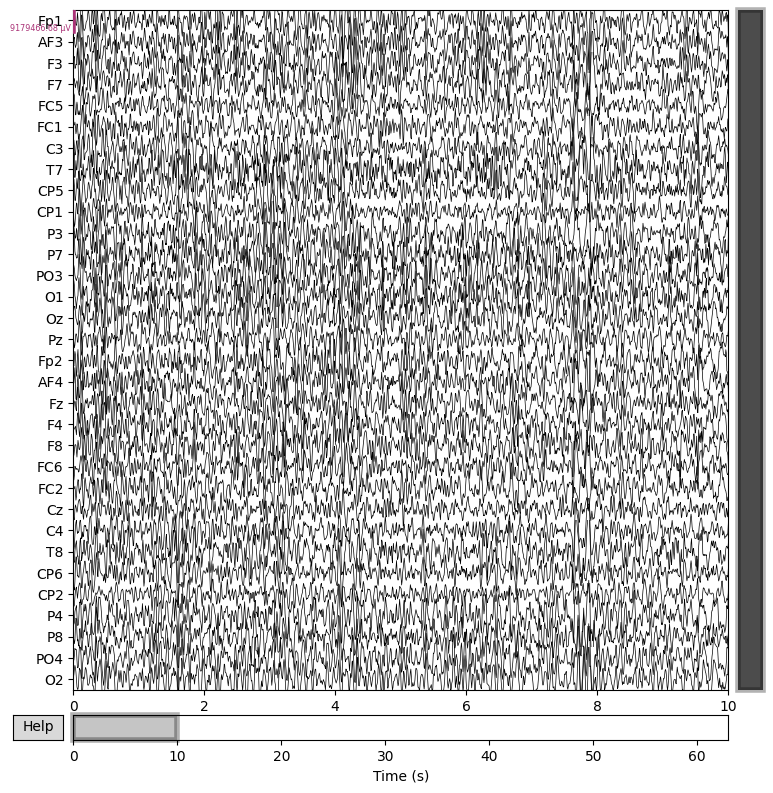

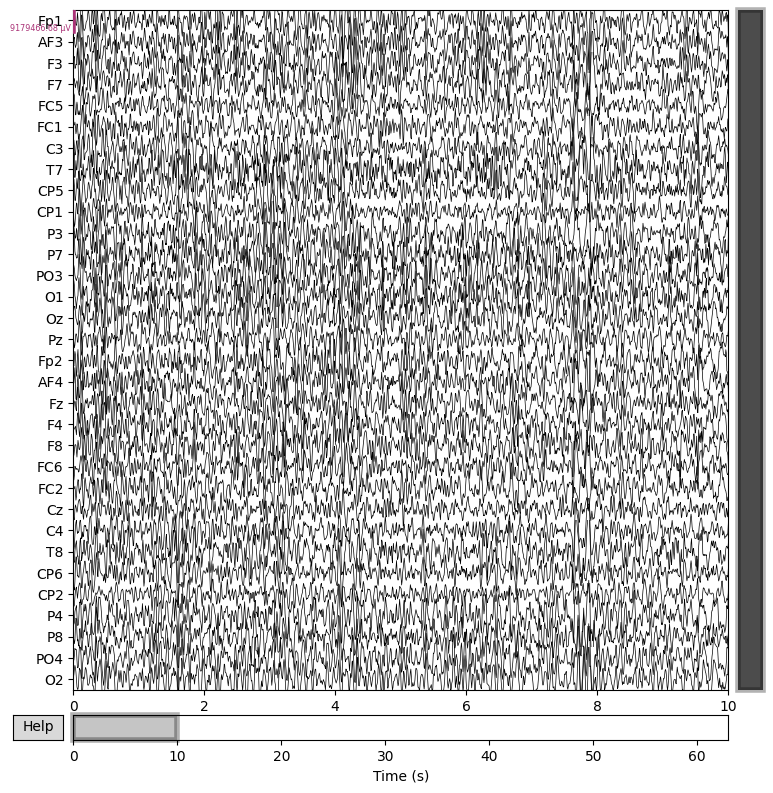

In [ ]:
!pip install mne
import mne

eeg_data = s01_data['data'][:, :32, :]  # Chỉ lấy 32 kênh EEG (bỏ EOG)
sampling_rate = 128  # DEAP dataset sử dụng 128 Hz

# Lấy dữ liệu của trial đầu tiên
trial_0 = eeg_data[0]  # shape: (32, 8064)

ch_names = ['Fp1','AF3','F3','F7','FC5','FC1','C3','T7','CP5','CP1','P3','P7','PO3','O1','Oz',
            'Pz','Fp2','AF4','Fz','F4','F8','FC6','FC2','Cz','C4','T8','CP6','CP2','P4','P8','PO4','O2']
ch_types = ['eeg'] * 32

# Tạo info
info = mne.create_info(ch_names=ch_names, sfreq=sampling_rate, ch_types=ch_types)

# Tạo RawArray
raw = mne.io.RawArray(trial_0, info)

# Đặt montage chuẩn 10-20 nếu cần
raw.set_montage('standard_1020', match_case=False)

# Hiển thị dữ liệu
raw.plot(n_channels=32, duration=10, scalings='auto', title="Trial 0 - EEG", show=True)

Creating RawArray with float64 data, n_channels=14, n_times=8064
    Range : 0 ... 8063 =      0.000 ...    62.992 secs
Ready.


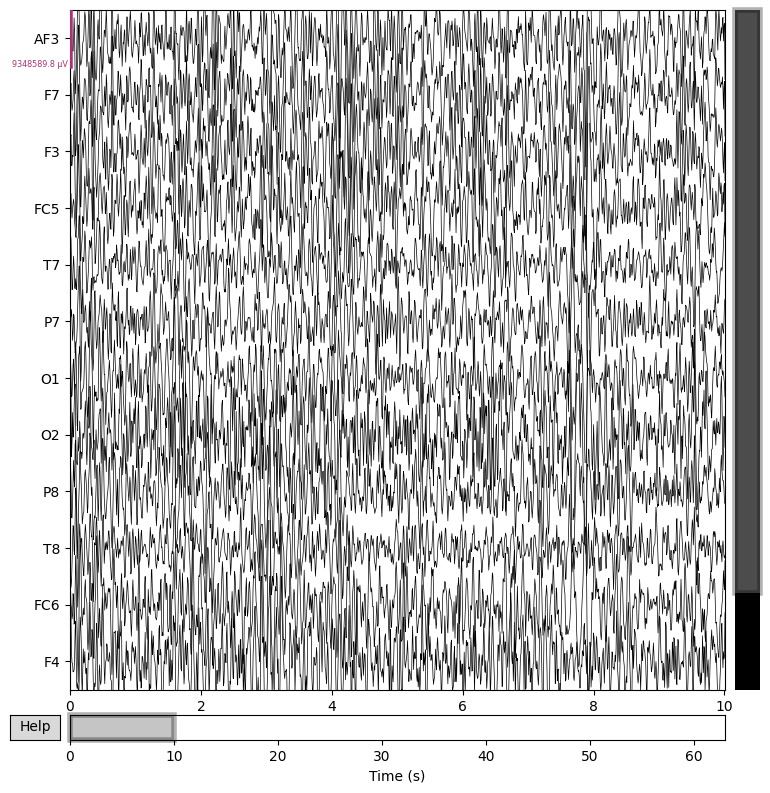

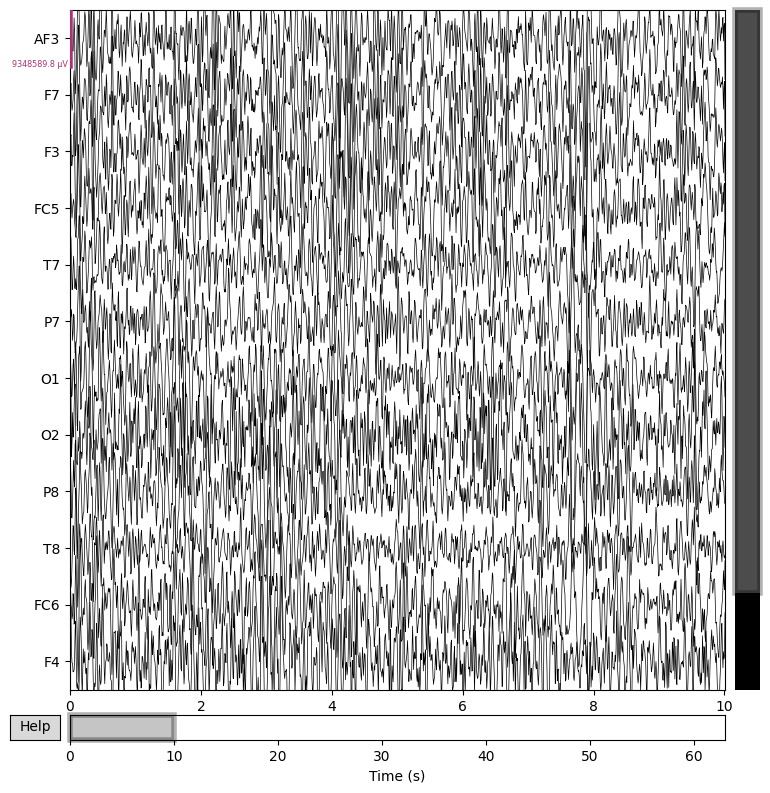

In [ ]:
eeg_data_selected = s01_data['data'][:, :14, :]  # Chỉ lấy 12 kênh EEG
sampling_rate = 128  # DEAP dataset sử dụng 128 Hz

# Lấy dữ liệu của trial đầu tiên
trial_0_selected = eeg_data_selected[0]  # shape: (14, 8064)
ch_names_selected = ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1',
                    'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
ch_types_selected = ['eeg'] * 14

# Tạo info
info = mne.create_info(ch_names=ch_names_selected, sfreq=sampling_rate, ch_types=ch_types_selected)

# Tạo RawArray
raw_selected = mne.io.RawArray(trial_0_selected, info)

# Đặt montage chuẩn 10-20 nếu cần
raw_selected.set_montage('standard_1020', match_case=False)

# Hiển thị dữ liệu
raw_selected.plot(n_channels=12, duration=10, scalings='auto', title="Trial 0 - EEG", show=True)

In [ ]:
selected_indices = [ch_names.index(ch) for ch in ch_names_selected]
eeg_data_selected = eeg_data[:, selected_indices, :]

In [ ]:
def four_labels (valence, arousal):
    if valence < 5:
        if arousal >= 5:
            return 0  # HANV
        else:
            return 1  # LANV
    else:
        if arousal >= 5:
            return 2  # HAPV
        else:
            return 3  # LAPV


In [ ]:
emotion_label_to_text = { 0: "HANV (High Arousal_Negative Valence)",  # Angry, Frustrated
    1: "LANV (Low Arousal_Negative Valence)",   # Depressed, Bored
    2: "HAPV (High Arousal_Positive Valence)",  # Excited, Happy
    3: "LAPV (Low Arousal_Positive Valence)" # Relaxed, Calm
                          }

In [ ]:
from sklearn.preprocessing import StandardScaler
def add_gaussian_noise(data, mean=0.0, std=0.05):
    noise = np.random.normal(mean, std, data.shape)
    return data + noise
def zscore_normalize(x):
    # Chuẩn hóa z-score theo từng kênh (channel-wise)
    return (x - x.mean(axis=1, keepdims=True)) / (x.std(axis=1, keepdims=True) + 1e-8)

In [ ]:
folder_path = "//content//drive//MyDrive//data_preprocessed_python"
file_path = "//content//drive//MyDrive//data_preprocessed_python//s01.dat"

class EEGDataset(Dataset):
    def __init__(self, folder_path=None, segments=None, labels=None, segment_length=384, augment=False ):
        self.segments = []
        self.labels = []
        self.augment = augment

        if segments is not None and labels is not None:
            self.segments = segments
            self.labels = labels

        elif folder_path is not None:

            ch_names = ['Fp1','AF3','F3','F7','FC5','FC1','C3','T7','CP5','CP1','P3','P7','PO3','O1','Oz',
            'Pz','Fp2','AF4','Fz','F4','F8','FC6','FC2','Cz','C4','T8','CP6','CP2','P4','P8','PO4','O2']
            ch_names_selected = ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1',
                                'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
            selected_indices = [ch_names.index(ch) for ch in ch_names_selected]
            for filename in sorted(os.listdir(folder_path)):
                if not filename.endswith(".dat"):
                    continue
                file_path = os.path.join(folder_path, filename)
                with open(file_path, 'rb') as f:
                    data = pk.load(f, encoding='latin1')
                    eeg_all = data['data']
                    labels_all = data['labels']

                    for trial_idx in range(40):
                        eeg = eeg_all[trial_idx, selected_indices, :]
                        eeg = zscore_normalize(eeg)

                        valence, arousal = labels_all[trial_idx][0], labels_all[trial_idx][1]
                        label = four_labels(valence, arousal)

                        stride = segment_length // 2
                        for start in range(0, eeg.shape[1] - segment_length + 1, stride):
                            segment = eeg[:, start:start+segment_length]
                            self.segments.append(segment)
                            self.labels.append(label)

    def __len__(self):
        return len(self.segments)

    def __getitem__(self, idx):
        x = self.segments[idx]
        y = self.labels[idx]

        if self.augment:
            x = add_gaussian_noise(x)

        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

In [ ]:
class EEGEmotionModel(torch.nn.Module):
    def __init__(self, dropout_rate = 0.5):
        super().__init__()
        # Đầu vào (B, 1, 14, 384)
        self.cnn_small = torch.nn.Sequential(
            torch.nn.Conv2d(1, 14, kernel_size=3, padding=1),
            torch.nn.BatchNorm2d(14),
            torch.nn.ELU(),
            torch.nn.MaxPool2d(2),  # => (B, 14, 7, 192)
            torch.nn.Dropout(dropout_rate/2)  # Thêm dropout sớm để regularization
        )

        self.cnn_large = torch.nn.Sequential(
            torch.nn.Conv2d(1, 14, kernel_size=5, padding=2),
            torch.nn.BatchNorm2d(14),
            torch.nn.ELU(),
            torch.nn.MaxPool2d(2),  # => (B, 14, 7, 192)
            torch.nn.Dropout(dropout_rate/2)
        )

        # Thêm tầng CNN thứ hai để trích xuất feature tốt hơn
        self.cnn_second = torch.nn.Sequential(
            torch.nn.Conv2d(28, 64, kernel_size=5, padding=2),
            torch.nn.BatchNorm2d(64),
            torch.nn.ELU(),
            torch.nn.MaxPool2d((2, 4)),  # => (B, 64, 3, 48)
            torch.nn.Dropout(dropout_rate)
        )

        # BiLSTM với attention mechanism
        self.bilstm = torch.nn.LSTM(
            input_size=64*3,  # 64 channels * 3 height
            hidden_size=128,   # Tăng hidden size
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3  # Dropout giữa các LSTM layers
        )

        # Attention mechanism
        self.attention = torch.nn.Sequential(
            torch.nn.Linear(256, 64),
            torch.nn.Tanh(),
            torch.nn.Linear(64, 1),
            torch.nn.Softmax(dim=1)
        )

        # Classifier với layer ẩn
        self.classifier = torch.nn.Sequential(
            torch.nn.Linear(256, 128),
            torch.nn.ELU(),
            torch.nn.Dropout(dropout_rate),
            torch.nn.Linear(128, 4)
        )

    def forward(self, x):
        # Input shape: (B, 14, 384)
        x = x.unsqueeze(1)  # (B, 1, 14, 384)

        # Hai nhánh CNN
        out1 = self.cnn_small(x)  # (B, 14, 7, 192)
        out2 = self.cnn_large(x)  # (B, 14, 7, 192)
        x = torch.cat([out1, out2], dim=1)  # (B, 28, 7, 192)

        # Tầng CNN thứ hai
        x = self.cnn_second(x)  # (B, 64, 3, 48)

        # Chuẩn bị cho LSTM
        x = x.permute(0, 3, 1, 2)  # (B, 48, 64, 3)
        x = x.reshape(x.size(0), x.size(1), -1)  # (B, 48, 192)

        # BiLSTM
        lstm_out, _ = self.bilstm(x)  # (B, 48, 256)

        # Attention mechanism
        attention_weights = self.attention(lstm_out)  # (B, 48, 1)
        attention_weights = attention_weights.transpose(1, 2)  # (B, 1, 48)
        context_vector = torch.bmm(attention_weights, lstm_out)  # (B, 1, 256)
        context_vector = context_vector.squeeze(1)  # (B, 256)

        # Classification
        return self.classifier(context_vector)

In [ ]:
BATCH_SIZE = 64

from sklearn.model_selection import train_test_split

full_dataset = EEGDataset(folder_path)
X = full_dataset.segments
y = full_dataset.labels

# Tách train (80%) và còn lại (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Tách tiếp val (10%) và test (10%) từ phần còn lại
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Tạo dataset tương ứng, chỉ augment cho tập train
train_dataset = EEGDataset(segments=X_train, labels=y_train, augment=True)
val_dataset   = EEGDataset(segments=X_val,   labels=y_val,   augment=False)
test_dataset  = EEGDataset(segments=X_test,  labels=y_test,  augment=False)

# Tạo DataLoader
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:

from collections import Counter

train_labels = train_dataset.labels
val_labels = val_dataset.labels
test_labels = test_dataset.labels

print("Train:", Counter(train_labels))
print("Val:", Counter(val_labels))
print("Test:", Counter(test_labels))

Train: Counter({2: 15022, 0: 9709, 3: 8725, 1: 8528})
Val: Counter({2: 1878, 0: 1213, 3: 1091, 1: 1066})
Test: Counter({2: 1878, 0: 1214, 3: 1090, 1: 1066})


In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
#Xử lý train_dataset
X_train = np.array(train_dataset.segments)
y_train = np.array(train_dataset.labels)

X_train_2d = X_train.reshape(X_train.shape[0], -1)

# Oversampling lớp thiểu số bằng SMOTE
#smote = SMOTE(sampling_strategy='not majority', random_state=42)
#X_over, y_over = smote.fit_resample(X_train_2d, y_train)

# Undersampling lớp quá nhiều bằng RandomUnderSampler
rus = RandomUnderSampler(sampling_strategy={2: 10000},random_state=42)
X_balanced, y_balanced = rus.fit_resample(X_train_2d, y_train)
X_balanced = X_balanced.reshape(-1, 14, 384)

# Gán lại dữ liệu vào train_dataset đã được tạo trước đó
train_dataset.segments = list(X_balanced)
train_dataset.labels = list(y_balanced)

In [ ]:
train_labels = train_dataset.labels

print("Train:", Counter(train_labels))

Train: Counter({np.int64(2): 10000, np.int64(0): 9709, np.int64(3): 8725, np.int64(1): 8528})


In [ ]:
model = EEGEmotionModel().to("cuda")
sample_input = torch.randn(2, 14, 384).to("cuda")  # Batch = 2
output = model(sample_input)
print(output.shape)

torch.Size([2, 4])


In [ ]:
!pip install torchinfo
from torchinfo import summary
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EEGEmotionModel().to(device)
summary(model, input_size=(32, 14, 384))

Layer (type:depth-idx)                   Output Shape              Param #
EEGEmotionModel                          [32, 4]                   --
├─Sequential: 1-1                        [32, 14, 7, 192]          --
│    └─Conv2d: 2-1                       [32, 14, 14, 384]         140
│    └─BatchNorm2d: 2-2                  [32, 14, 14, 384]         28
│    └─ELU: 2-3                          [32, 14, 14, 384]         --
│    └─MaxPool2d: 2-4                    [32, 14, 7, 192]          --
│    └─Dropout: 2-5                      [32, 14, 7, 192]          --
├─Sequential: 1-2                        [32, 14, 7, 192]          --
│    └─Conv2d: 2-6                       [32, 14, 14, 384]         364
│    └─BatchNorm2d: 2-7                  [32, 14, 14, 384]         28
│    └─ELU: 2-8                          [32, 14, 14, 384]         --
│    └─MaxPool2d: 2-9                    [32, 14, 7, 192]          --
│    └─Dropout: 2-10                     [32, 14, 7, 192]          --
├─Sequential:

In [ ]:
model.to(device)
criterion = torch.nn.CrossEntropyLoss()

def train(model, loader):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        train_loss = total_loss / len(loader)

        pred = out.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.size(0)
        train_acc = 100*correct/total

    return train_loss, train_acc

In [ ]:
import torch.nn.functional as F
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_probs = []
    all_labels = []
    all_preds = []
    total_loss = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)

            # Tính loss
            loss = criterion(out, y)
            total_loss += loss.item()

            # Xác suất cảm xúc
            probs = F.softmax(out, dim=1)
            all_probs.append(probs.cpu().numpy())

            # Lấy nhãn dự đoán
            pred = probs.argmax(dim=1)
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

            correct += (pred == y).sum().item()
            total += y.size(0)

    avg_loss = total_loss / len(loader)
    acc = 100 * correct / total

    results = {
        'loss': avg_loss,
        'accuracy': acc,
        'predictions': np.array(all_preds),
        'labels': np.array(all_labels),
        'probabilities': np.concatenate(all_probs, axis=0)
    }

    return results

In [ ]:
EPOCHS = 150
save_dir = "//content//drive//MyDrive//Colab Notebooks//Đồ án 2//EEG"

from torch.optim.lr_scheduler import ReduceLROnPlateau

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, factor=0.5, patience=10)

best_val_acc = 0

epochs_no_improve = 0

history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': [],
        'best_weights': None,
        'best_epoch': 0
    }
for epoch in range(EPOCHS):
    train_loss, train_acc = train(model, train_loader)
    val_results = evaluate(model, val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_results['loss'])
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_results['accuracy'])


    if val_results['accuracy'] > best_val_acc:
        best_val_acc = val_results['accuracy']
        history['best_epoch'] = epoch + 1
        epochs_no_improve = 0

        checkpoint = {
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_acc': best_val_acc,
        'history': history  # (tùy chọn) lưu toàn bộ lịch sử nếu muốn
          }

        torch.save(checkpoint, os.path.join(save_dir, 'eeg_model_best.pth'))

    else:
        epochs_no_improve += 1

    scheduler.step(val_results['loss'])
    print(f"Current learning rate: {scheduler.optimizer.param_groups[0]['lr']}")
    print(f"Epoch {epoch+1}/{EPOCHS} - Train Loss = {train_loss:.4f}, Train Acc = {train_acc:.4f} | Val Loss = {val_results['loss']:.4f}, Val Acc = {val_results['accuracy']:.4f}")


Current learning rate: 0.001
Epoch 1/150 - Train Loss = 1.0307, Train Acc = 54.6020 | Val Loss = 1.0241, Val Acc = 55.0877
Current learning rate: 0.001
Epoch 2/150 - Train Loss = 0.9985, Train Acc = 56.3119 | Val Loss = 0.9838, Val Acc = 57.2409
Current learning rate: 0.001
Epoch 3/150 - Train Loss = 0.9722, Train Acc = 57.7187 | Val Loss = 0.9553, Val Acc = 58.0221
Current learning rate: 0.001
Epoch 4/150 - Train Loss = 0.9435, Train Acc = 59.4367 | Val Loss = 0.9367, Val Acc = 59.6037
Current learning rate: 0.001
Epoch 5/150 - Train Loss = 0.9210, Train Acc = 60.4350 | Val Loss = 0.9251, Val Acc = 60.4992
Current learning rate: 0.001
Epoch 6/150 - Train Loss = 0.8963, Train Acc = 61.6823 | Val Loss = 0.9006, Val Acc = 60.9375
Current learning rate: 0.001
Epoch 7/150 - Train Loss = 0.8782, Train Acc = 62.3884 | Val Loss = 0.9193, Val Acc = 60.6898
Current learning rate: 0.001
Epoch 8/150 - Train Loss = 0.8561, Train Acc = 63.6113 | Val Loss = 0.8932, Val Acc = 61.1471
Current learning

In [ ]:
print(best_val_acc)

79.0967987804878


In [ ]:
torch.save(model.state_dict(), '//content//drive//MyDrive//Colab Notebooks//Đồ án 2//EEG//eeg_model_best.pth')

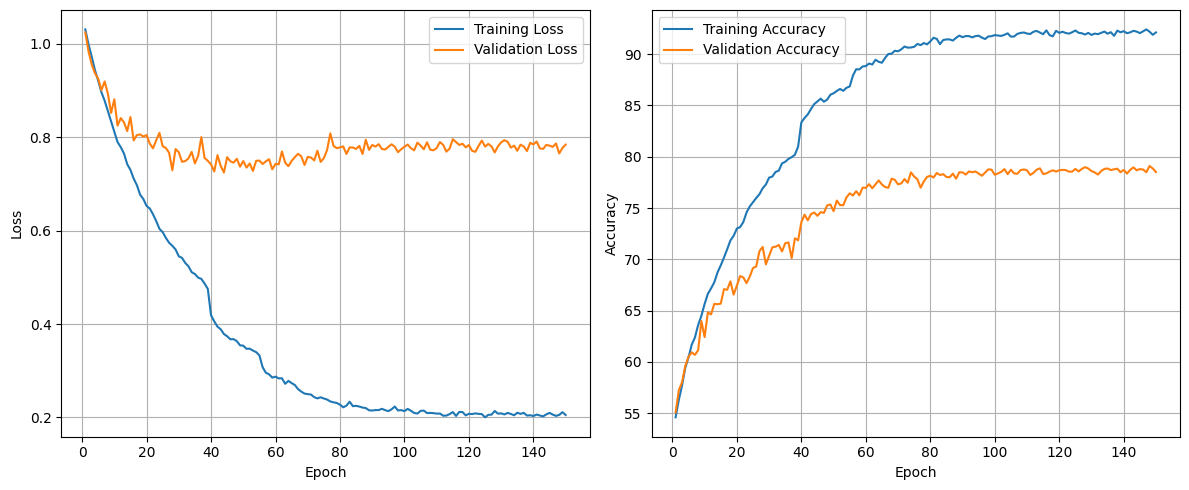

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], label='Training Loss')
plt.plot(epochs, history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)


# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], label='Training Accuracy')
plt.plot(epochs, history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epoch',)
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Test Accuracy: 78.11%

Classification Report:
              precision    recall  f1-score   support

        HANV       0.77      0.79      0.78      1214
        LANV       0.76      0.79      0.77      1066
        HAPV       0.84      0.76      0.80      1878
        LAPV       0.73      0.80      0.76      1090

    accuracy                           0.78      5248
   macro avg       0.77      0.78      0.78      5248
weighted avg       0.78      0.78      0.78      5248



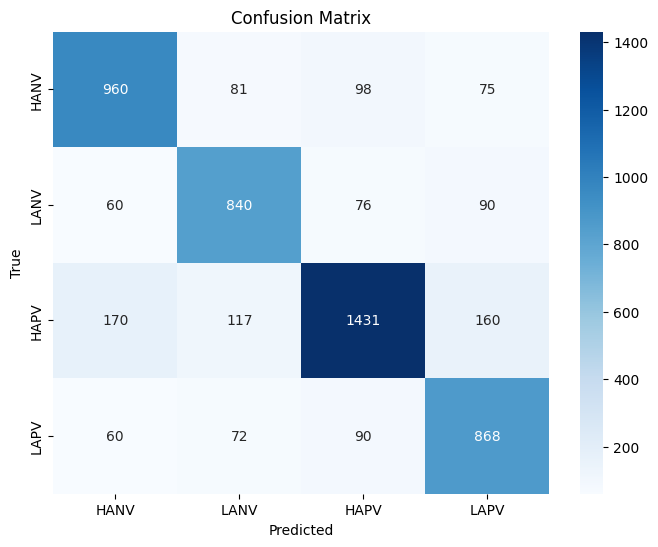

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
def test_model(model, test_loader, device):
    """
    Đánh giá mô hình trên test set và hiển thị các metrics quan trọng

    Args:
        model: Mô hình đã được huấn luyện
        test_loader: DataLoader chứa dữ liệu test
        device: Thiết bị tính toán (cuda/cpu)
    """
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Chuyển đổi sang numpy array
    all_probs = np.concatenate(all_probs, axis=0)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    # Tính các metrics
    accuracy = np.mean(all_preds == all_labels)
    print(f"\nTest Accuracy: {accuracy*100:.2f}%\n")

    # Classification report
    class_names = ['HANV', 'LANV', 'HAPV', 'LAPV']
    print("Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

# Sử dụng hàm test
if __name__ == "__main__":
    # Load model tốt nhất đã lưu
    model = EEGEmotionModel().to(device)
    model.load_state_dict(torch.load("//content//drive//MyDrive//Colab Notebooks//Đồ án 2//EEG//eeg_model_best.pth"))
    model.eval()

    # Đánh giá trên test set
    test_results = test_model(model, test_loader, device)


Error loading model state dictionary: 'model_state_dict'
Model state dictionary loaded directly from //content//drive//MyDrive//Colab Notebooks//Đồ án 2//EEG//eeg_model.pth


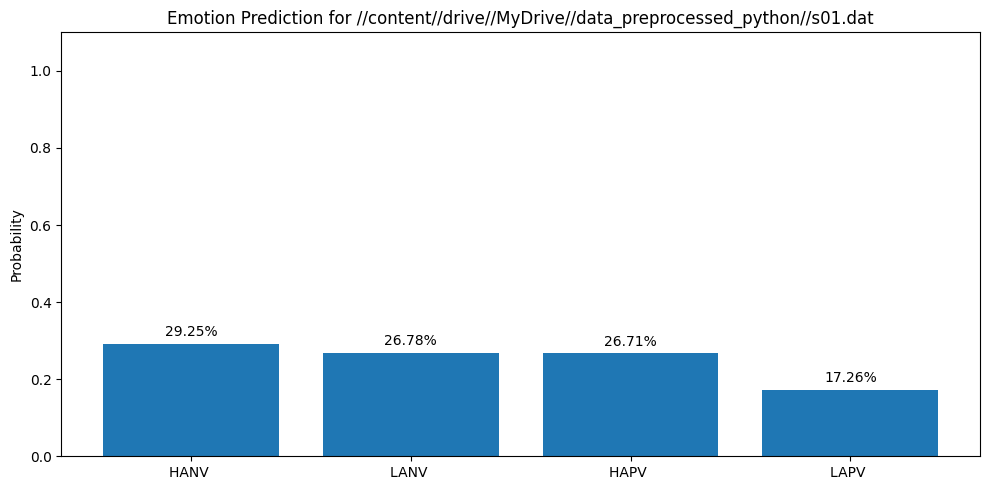


=== EEG Emotion Prediction Results ===
File: //content//drive//MyDrive//data_preprocessed_python//s01.dat

Final Prediction: HANV 

Probability Distribution:
- HANV : 29.25%
- LANV : 26.78%
- HAPV : 26.71%
- LAPV : 17.26%


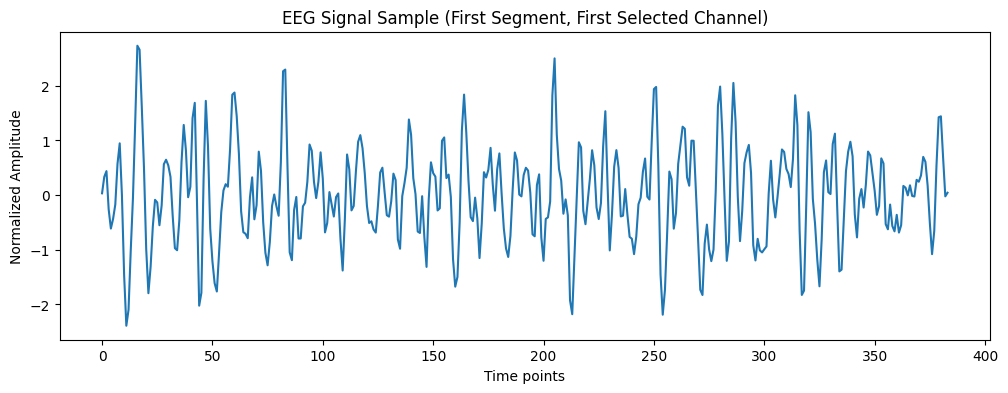

In [ ]:
import numpy as np
import torch
import pickle as pk
import os
import matplotlib.pyplot as plt
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Ensure necessary imports are present for the functions
# from your previous cells if they are not already here.
# e.g., from . import EEGEmotionModel, zscore_normalize, four_labels, emotion_label_to_text # or wherever these are defined

# Redefine the selected channels list
ch_names = ['Fp1','AF3','F3','F7','FC5','FC1','C3','T7','CP5','CP1','P3','P7','PO3','O1','Oz',
            'Pz','Fp2','AF4','Fz','F4','F8','FC6','FC2','Cz','C4','T8','CP6','CP2','P4','P8','PO4','O2']
ch_names_selected = ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1',
                     'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
selected_indices = [ch_names.index(ch) for ch in ch_names_selected]


def zscore_normalize(x):
    # Ensure this function is correctly defined and imported/present
    # For demonstration, adding a placeholder if it's not from a previous cell
    # This implementation is assumed based on the dataset class
    return (x - x.mean(axis=-1, keepdims=True)) / (x.std(axis=-1, keepdims=True) + 1e-8)


def load_and_preprocess_single_file(file_path, model_input_size=384):
    """
    Tải và tiền xử lý 1 file .dat để đưa vào mô hình,
    chia thành các segment và chọn kênh.
    """
    with open(file_path, 'rb') as f:
        data = pk.load(f, encoding='latin1')

    eeg_all_trials = data['data']  # Shape (40, 32, 8064)

    all_segments = []

    # Xử lý từng trial trong file
    for trial_idx in range(eeg_all_trials.shape[0]):
        # Lấy dữ liệu EEG cho trial hiện tại và chọn kênh
        eeg_trial = eeg_all_trials[trial_idx, selected_indices, :] # Shape (14, 8064)

        # Chuẩn hóa z-score theo từng kênh cho trial này
        # Normalizing across time axis (-1) for each channel
        eeg_trial = zscore_normalize(eeg_trial) # Shape (14, 8064)

        # Chia trial thành các segment
        num_segments_per_trial = eeg_trial.shape[1] // model_input_size

        for i in range(num_segments_per_trial):
            start = i * model_input_size
            # Lấy segment cho trial hiện tại
            segment = eeg_trial[:, start:start+model_input_size] # Shape (14, 384)
            all_segments.append(segment)

    # Kết quả là một danh sách các segment từ tất cả các trial
    return np.array(all_segments) # Shape (Total_Segments, 14, 384)


def predict_single_file(model, file_path, device):
    """
    Dự đoán cảm xúc từ 1 file .dat
    """
    # Load và tiền xử lý dữ liệu
    segments = load_and_preprocess_single_file(file_path) # Shape (Total_Segments, 14, 384)

    if segments.shape[0] == 0:
        print(f"No segments found in {file_path}")
        return None # or handle appropriately

    # Chuyển sang tensor
    # segments_tensor shape should be (Total_Segments, 14, 384)
    segments_tensor = torch.tensor(segments, dtype=torch.float32).to(device)

    # Dự đoán
    model.eval()
    with torch.no_grad():
        # Input to model.forward will be (Total_Segments, 14, 384)
        # model.forward will unsqueeze to (Total_Segments, 1, 14, 384)
        outputs = model(segments_tensor) # outputs shape (Total_Segments, 4)
        probs = torch.softmax(outputs, dim=1) # probs shape (Total_Segments, 4)
        _, preds = torch.max(outputs, 1) # preds shape (Total_Segments)

    # Lấy kết quả trung bình từ tất cả các segments
    avg_probs = probs.mean(dim=0).cpu().numpy() # Shape (4,)
    final_pred = np.argmax(avg_probs)

    return {
        'segments_predictions': preds.cpu().numpy(), # Shape (Total_Segments,)
        'segments_probabilities': probs.cpu().numpy(), # Shape (Total_Segments, 4)
        'average_probabilities': avg_probs, # Shape (4,)
        'final_prediction': final_pred # scalar
    }

def visualize_results(results, file_path):
    """
    Hiển thị kết quả dự đoán
    """
    if results is None:
        print("No results to visualize.")
        return

    emotion_labels = {
        0: "HANV ",
        1: "LANV ",
        2: "HAPV ",
        3: "LAPV "
    }

    # Lấy tên cảm xúc dự đoán
    pred_label = emotion_labels[results['final_prediction']]

    # Vẽ biểu đồ xác suất
    plt.figure(figsize=(10, 5))
    plt.bar(emotion_labels.values(), results['average_probabilities'])
    plt.title(f"Emotion Prediction for {file_path}")
    plt.ylabel("Probability")
    plt.ylim(0, 1.1) # Adjust ylim slightly for text
    for i, prob in enumerate(results['average_probabilities']):
        plt.text(i, prob+0.02, f"{prob:.2%}", ha='center')
    plt.xticks(rotation=0) # Keep x-axis labels horizontal
    plt.tight_layout() # Adjust layout to prevent overlap
    plt.show()

    # Hiển thị kết quả chi tiết
    print("\n=== EEG Emotion Prediction Results ===")
    print(f"File: {file_path}")
    print(f"\nFinal Prediction: {pred_label}")
    print("\nProbability Distribution:")
    for i, label in emotion_labels.items():
        print(f"- {label}: {results['average_probabilities'][i]:.2%}")

    # Hiển thị 1 kênh EEG mẫu từ dữ liệu được load và tiền xử lý (lấy segment đầu tiên)
    # Re-load data specifically for plotting, ensuring it's just the EEG part
    try:
        segments_for_plot = load_and_preprocess_single_file(file_path)
        if segments_for_plot.shape[0] > 0:
            plt.figure(figsize=(12, 4))
            # Plot the first channel of the first segment
            plt.plot(segments_for_plot[0][0])
            plt.title("EEG Signal Sample (First Segment, First Selected Channel)")
            plt.xlabel("Time points")
            plt.ylabel("Normalized Amplitude")
            plt.show()
        else:
             print("Could not plot EEG sample: No segments generated.")
    except Exception as e:
         print(f"Could not plot EEG sample due to error: {e}")



# Sử dụng
if __name__ == "__main__":
    # Load model
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = EEGEmotionModel().to(device)
    # Load the best model weights saved during training
    checkpoint_path = "//content//drive//MyDrive//Colab Notebooks//Đồ án 2//EEG//eeg_model.pth"
    try:

        checkpoint = torch.load(checkpoint_path)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Model state dictionary loaded from {checkpoint_path}")
    except Exception as e:
        print(f"Error loading model state dictionary: {e}")
        # Fallback if it was just the state_dict saved directly
        try:
             model.load_state_dict(torch.load(checkpoint_path))
             print(f"Model state dictionary loaded directly from {checkpoint_path}")
        except Exception as e_fallback:
             print(f"Fallback loading failed: {e_fallback}")
             print("Could not load model. Please check the path and file content.")
             exit() # Exit if model loading fails completely


    model.eval() # Set model to evaluation mode

    # File cần test
    test_file = "//content//drive//MyDrive//data_preprocessed_python//s01.dat"  # Thay bằng đường dẫn file của bạn

    # Dự đoán
    results = predict_single_file(model, test_file, device)

    # Hiển thị kết quả
    visualize_results(results, test_file)